## CONSUMER SHOPPING BEHAVIOR

In [4]:
#import libraries
import numpy
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [5]:
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [2]:
#read dataset
df = pd.read_csv('consumer_dataset.csv')
df.head(10)

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both
5,6,11/07/2026 00:16:12,32,Male,Employed full-time,Egypt,"$1,000-3,000",Equal mix,Occasionally,Physical stores,...,Often,$500+,Digital wallet,"No, never",4.0,8.0,1.0,Better prices,No delivery wait,Offline
6,7,24/07/2026 23:10:04,21,Prefer not to say,Student,India,"Under $1,000",Equal mix,Occasionally,Local e-commerce,...,Sometimes,Under $50,Credit Card,"Yes, occasionally",8.0,3.0,1.0,More variety,No delivery wait,Online
7,8,19/07/2026 23:47:44,18,Female,Student,India,"Under $1,000",Equal mix,Occasionally,Global marketplace (Amazon etc.),...,Sometimes,$50-150,Credit Card,"Yes, occasionally",5.0,5.0,3.0,Better prices,No delivery wait,Equal / both
8,9,20/07/2026 15:49:25,18,NaN,Student,Indonesia,"$1,000-3,000",Equal mix,Occasionally,Global marketplace (Amazon etc.),...,Sometimes,$50-150,Digital wallet,"No, never",8.0,3.0,3.0,Convenience,No delivery wait,Offline
9,10,30/07/2026 11:38:27,20,Female,Student,Brazil,"Under $1,000",NaN,Rarely,Physical stores,...,Sometimes,$150-300,Digital wallet,"Yes, regularly",7.0,8.0,2.0,More variety,No delivery wait,Equal / both


In [3]:
#checking for null values
df.isnull().sum()

Response_ID                            0
Timestamp                              0
Age                                   22
Gender                                16
Occupation_Status                     21
Country_Region                        20
Monthly_Income_Range                  21
Shop_Most_Where                       16
Online_Shopping_Frequency             19
Preferred_Platform                    14
Primary_Device                         8
Top_Spending_Category                 24
Review_Influence_Score                15
Social_Ads_Influence_Score            21
Price_Comparison_Frequency            26
Discount_Importance_Score             23
Follows_Brands_On_Social              11
Likely_To_Buy_After_Ad_Score          25
Makes_Shopping_List                   24
Impulse_Purchase_Frequency            16
Return_Frequency                      17
Avg_Monthly_Spend_NonEssentials       20
Preferred_Payment_Method              15
Uses_BNPL_Installments                12
Online_Shopping_

In [6]:
df.shape

(500, 30)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    object 
 2   Age                                 478 non-null    object 
 3   Gender                              484 non-null    object 
 4   Occupation_Status                   479 non-null    object 
 5   Country_Region                      480 non-null    object 
 6   Monthly_Income_Range                479 non-null    object 
 7   Shop_Most_Where                     484 non-null    object 
 8   Online_Shopping_Frequency           481 non-null    object 
 9   Preferred_Platform                  486 non-null    object 
 10  Primary_Device                      492 non-null    object 
 11  Top_Spending_Category               476 non-n

In [8]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Timestamp'] = pd.to_datetime(df['Timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

In [10]:
df[['Age', 'Timestamp']].dtypes

Age                 float64
Timestamp    datetime64[ns]
dtype: object

In [11]:
df['Age'].describe()

count    470.000000
mean      25.019149
std        7.515276
min       16.000000
25%       20.000000
50%       22.000000
75%       30.000000
max       50.000000
Name: Age, dtype: float64

In [12]:
df['Reason_Prefer_Online'].value_counts()

Reason_Prefer_Online
More variety      170
Convenience       157
Better prices      81
Not applicable     38
Name: count, dtype: int64

In [13]:
#place age in groups
bins = [0, 18, 25, 35, 45, 55, 65, 100]
labels = ['0-17', '18-24', '25-34', '35-44', '45-54', '55-64', '65+']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=False)

In [14]:
df['Age_Group'].value_counts()

Age_Group
18-24    260
25-34    116
35-44     49
0-17      33
45-54     12
55-64      0
65+        0
Name: count, dtype: int64

In [15]:
df.columns

Index(['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status',
       'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where',
       'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device',
       'Top_Spending_Category', 'Review_Influence_Score',
       'Social_Ads_Influence_Score', 'Price_Comparison_Frequency',
       'Discount_Importance_Score', 'Follows_Brands_On_Social',
       'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List',
       'Impulse_Purchase_Frequency', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode',
       'Age_Group'],
      dtype='object')

In [16]:
cols_to_fill = ['Gender', 'Occupation_Status','Country_Region','Shop_Most_Where','Preferred_Platform','Preferred_Payment_Method']


In [18]:
for col in cols_to_fill:
    df[col] = df[col].fillna('unknown')

In [19]:
df[cols_to_fill].isnull().sum()

Gender                      0
Occupation_Status           0
Country_Region              0
Shop_Most_Where             0
Preferred_Platform          0
Preferred_Payment_Method    0
dtype: int64

In [20]:
df.columns

Index(['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status',
       'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where',
       'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device',
       'Top_Spending_Category', 'Review_Influence_Score',
       'Social_Ads_Influence_Score', 'Price_Comparison_Frequency',
       'Discount_Importance_Score', 'Follows_Brands_On_Social',
       'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List',
       'Impulse_Purchase_Frequency', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode',
       'Age_Group'],
      dtype='object')

In [21]:
last6 = [ 'Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode',
       'Age_Group']

In [24]:
dropoff = df[last6].isna().all(axis=1)

In [25]:
dropoff.sum

<bound method Series.sum of 0      False
1      False
2      False
3      False
4      False
       ...  
495    False
496    False
497    False
498    False
499    False
Length: 500, dtype: bool>

In [27]:
df.loc[dropoff, 'Timestamp'].dt.date.value_counts().sort_index()

Series([], Name: count, dtype: int64)

In [28]:
pd.crosstab(df['Shop_Most_Where'], df['Reason_Prefer_InStore'], dropna = False)

Reason_Prefer_InStore,No delivery wait,Not applicable,Trust,Try product before buying,NaN
Shop_Most_Where,,,,,
Equal mix,54,42,49,74,29
In-store only,15,10,16,21,9
Online only,43,20,51,46,5
unknown,7,0,3,4,2


In [31]:
age_summary = df.groupby('Age_Group', observed = True).agg(
    avd_satisfaction = ('Online_Shopping_Satisfaction_Score', 'mean'),
    avd_trust = ('Trust_In_Online_Reviews_Score', 'mean'),
    avd_regret = ('Regret_After_Purchase_Frequency', 'mean'),
    respondents = ('Response_ID', 'count')
).round(2).reset_index()

In [32]:
age_summary

,Age_Group,avd_satisfaction,avd_trust,avd_regret,respondents
0,0-17,7.60,6.83,2.10,33
1,18-24,7.05,5.94,2.25,260
2,25-34,7.09,6.33,2.17,116
3,35-44,7.12,6.50,1.95,49
4,45-54,7.00,5.45,2.18,12


In [33]:
top_countries = df['Country_Region'].value_counts().head(10).index.tolist()

In [34]:
country_summary = df[df['Country_Region'].isin(top_countries)].groupby('Country_Region', observed = True).agg(
    avd_satisfaction = ('Online_Shopping_Satisfaction_Score', 'mean'),
    avd_trust = ('Trust_In_Online_Reviews_Score', 'mean'),
    avd_regret = ('Regret_After_Purchase_Frequency', 'mean'),
    respondents = ('Response_ID', 'count')
).round(2).reset_index()

In [35]:
country_summary

,Country_Region,avd_satisfaction,avd_trust,avd_regret,respondents
0,Brazil,7.11,6.81,2.15,38
1,Egypt,6.52,6.45,2.05,25
2,India,6.78,5.66,2.30,66
3,Indonesia,7.43,6.30,2.18,26
4,Kenya,7.24,5.64,2.21,26
5,Mexico,7.25,6.15,2.10,35
6,Nigeria,6.95,6.24,2.10,23
7,Pakistan,7.84,6.37,2.50,23
8,Philippines,7.09,6.30,1.83,23
9,United States,7.39,6.47,2.11,56


In [48]:
occupation_summary = df.groupby('Occupation_Status').agg(
    avd_impulse = ('Impulse_Purchase_Frequency', 'mean'),
    avd_discount = ('Discount_Importance_Score', 'mean'),
    bnpl_rate = ('Uses_BNPL_Installments', lambda x: (x == 'Yes, regularly').mean()),
    respondents = ('Response_ID', 'count')
).round(2).sort_values('avd_impulse', ascending = False).reset_index()

In [49]:
occupation_summary

,Occupation_Status,avd_impulse,avd_discount,bnpl_rate,respondents
0,Employed part-time,2.86,3.94,0.10,71
1,Student,2.61,3.80,0.13,238
2,unknown,2.50,3.67,0.05,21
3,Employed full-time,2.46,3.90,0.14,118
4,Self-employed,2.45,3.78,0.12,33
5,Unemployed,2.44,3.47,0.05,19


In [50]:
pivot_payment = pd.pivot_table(
    df, index = 'Shop_Most_Where', columns = 'Preferred_Payment_Method', values = 'Response_ID', aggfunc = 'count', fill_value = 0  
)

In [52]:
pivot_payment_pct = pivot_payment.div(pivot_payment.sum(axis=1), axis=0).round(2)
pivot_payment_pct

Preferred_Payment_Method,Cash,Credit Card,Debit Card,Digital wallet,unknown
Shop_Most_Where,,,,,
Equal mix,0.14,0.21,0.27,0.35,0.02
In-store only,0.14,0.25,0.23,0.34,0.04
Online only,0.11,0.22,0.24,0.39,0.03
unknown,0.12,0.12,0.31,0.38,0.06


In [54]:
pivot_gender_spend = pd.pivot_table(
    df, index = 'Gender', columns = 'Top_Spending_Category', values = 'Response_ID', aggfunc = 'count', fill_value = 0)

In [56]:
pivot_gender_spend_pct = pivot_gender_spend.div(pivot_gender_spend.sum(axis=1), axis=0).round(2)
pivot_gender_spend_pct

Top_Spending_Category,Beauty & personal care,Books,Clothing,Electronics,Groceries,miscellaneous
Gender,,,,,,
Female,0.06,0.09,0.38,0.14,0.21,0.12
Male,0.08,0.07,0.40,0.16,0.18,0.10
Prefer not to say,0.10,0.10,0.22,0.24,0.18,0.14
unknown,0.00,0.13,0.40,0.13,0.20,0.13


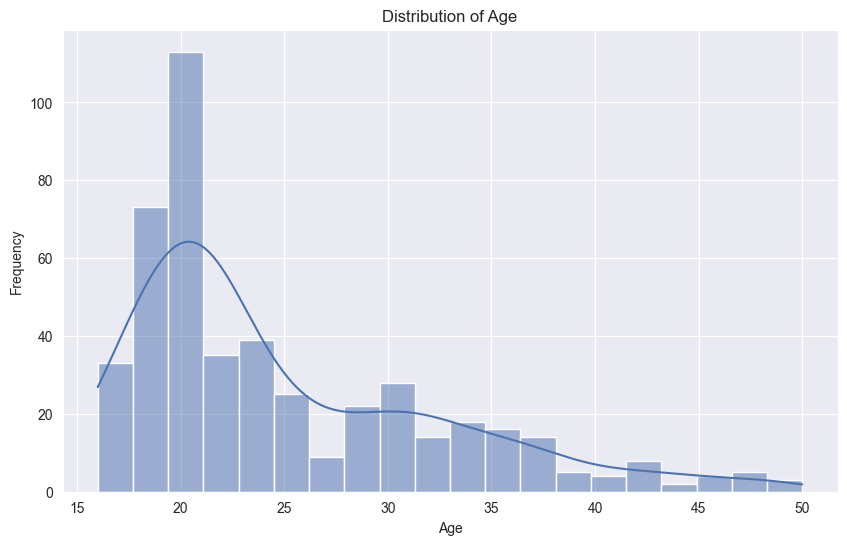

In [57]:
sns.histplot(df['Age'].dropna(), bins = 20, kde = True, color = '#4C72B0')
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

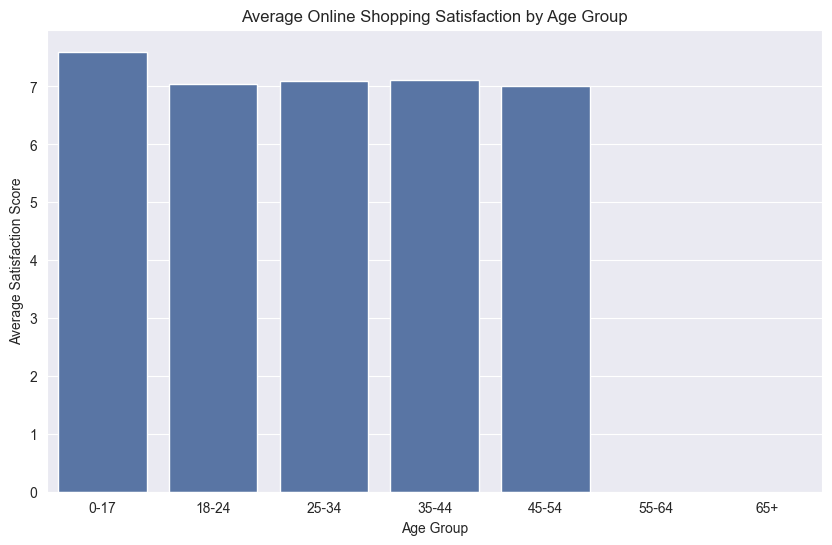

In [58]:
sns.barplot(x = age_summary['Age_Group'], y = age_summary['avd_satisfaction'], color = '#4C72B0')
plt.title('Average Online Shopping Satisfaction by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Satisfaction Score')
plt.show()

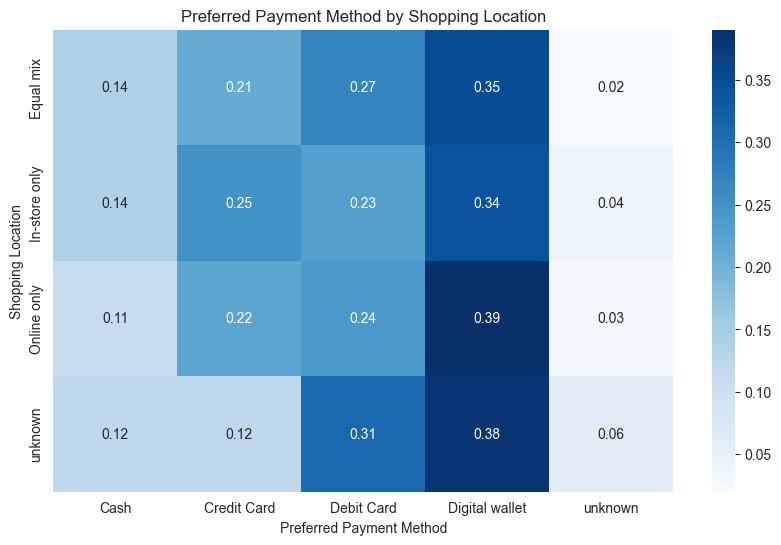

In [59]:
sns.heatmap(pivot_payment_pct, annot = True, fmt = '.2f', cmap = 'Blues')
plt.title('Preferred Payment Method by Shopping Location')
plt.xlabel('Preferred Payment Method')
plt.ylabel('Shopping Location')
plt.show()

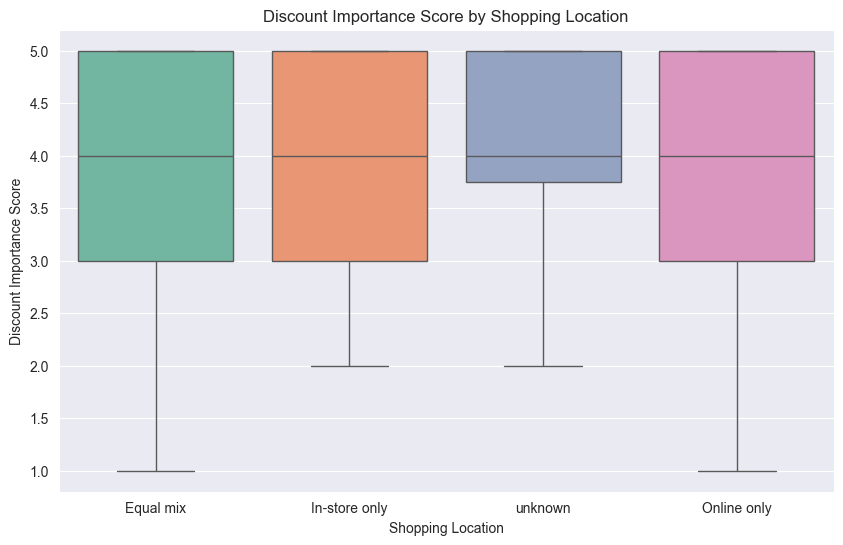

In [60]:
sns.boxplot(x = 'Shop_Most_Where', y = 'Discount_Importance_Score', data = df, palette = 'Set2')
plt.title('Discount Importance Score by Shopping Location')
plt.xlabel('Shopping Location') 
plt.ylabel('Discount Importance Score')
plt.show()